# Environmental Sound Analysis: Rain

**Question:** How does STFT window length affect the time-frequency representation of the rain recording, and what can be observed using 512 and 2048 samples?

**Selected recording:** `rain.wav` (5 seconds, originally 44.1 kHz, mono). It was resampled to 16 kHz for this analysis. The supplied set also contains `clock.wav`, `dog.wav`, and `fire.wav`; only one recording is required.

Both STFTs use a **160-sample hop (10 ms)** and a Hann window. This notebook plots waveform, average frequency spectrum, spectrograms, and a focused interval. It also records the main observations and one limitation.


In [1]:
from pathlib import Path
import numpy as np
import soundfile as sf
import matplotlib.pyplot as plt
from scipy.signal import resample_poly, stft, welch
from math import gcd

AUDIO_FILE = "rain.wav"
AUDIO_PATH = Path("audio") / AUDIO_FILE
if not AUDIO_PATH.exists():
    AUDIO_PATH = Path(AUDIO_FILE)
if not AUDIO_PATH.exists():
    raise FileNotFoundError("Put rain.wav in audio/ or in the same folder as this notebook.")

TARGET_SR = 16_000
HOP = 160
WINDOWS = [512, 2048]
RESULTS = Path("results")
RESULTS.mkdir(exist_ok=True)

x, original_sr = sf.read(AUDIO_PATH)
if x.ndim == 2:
    x = x.mean(axis=1)
g = gcd(original_sr, TARGET_SR)
if original_sr != TARGET_SR:
    x = resample_poly(x, TARGET_SR // g, original_sr // g)
sr = TARGET_SR
x = x.astype(float)
x = x / (np.max(np.abs(x)) + 1e-12)
time = np.arange(len(x)) / sr
duration = len(x) / sr

print(f"Audio filename: {AUDIO_FILE}")
print(f"Original sample rate: {original_sr} Hz")
print(f"Analysis sample rate: {sr} Hz")
print(f"Duration: {duration:.2f} s")
print(f"Samples after resampling: {len(x)}")


Audio filename: rain.wav
Original sample rate: 44100 Hz
Analysis sample rate: 16000 Hz
Duration: 5.00 s
Samples after resampling: 80000


## 1. Waveform\nThe waveform shows the normalized amplitude over time. Rain is continuous rather than consisting of silence with one isolated event. Some amplitude fluctuations and peaks are visible.

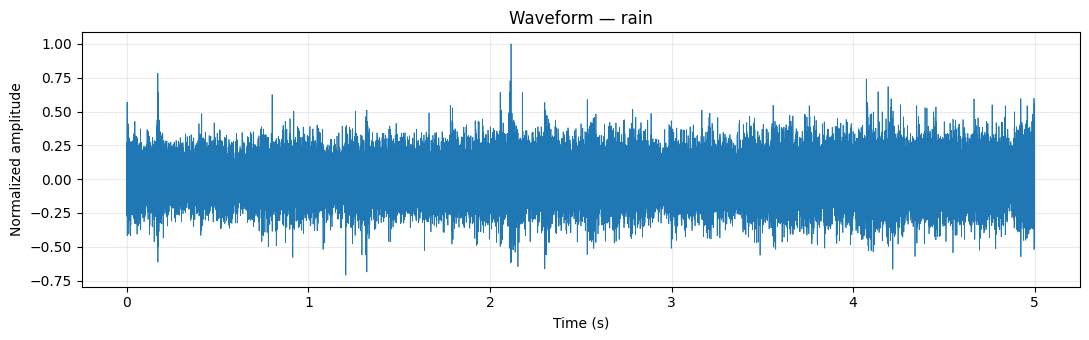

In [2]:
plt.figure(figsize=(11, 3.5))
plt.plot(time, x, linewidth=0.55)
plt.xlabel("Time (s)")
plt.ylabel("Normalized amplitude")
plt.title("Waveform — rain")
plt.grid(alpha=0.25)
plt.tight_layout()
plt.savefig(RESULTS / "waveform.png", dpi=200)
plt.show()


## 2. Average frequency spectrum\nThe spectrum is an overall summary of how energy is distributed across frequency. It does not show when a frequency occurs.

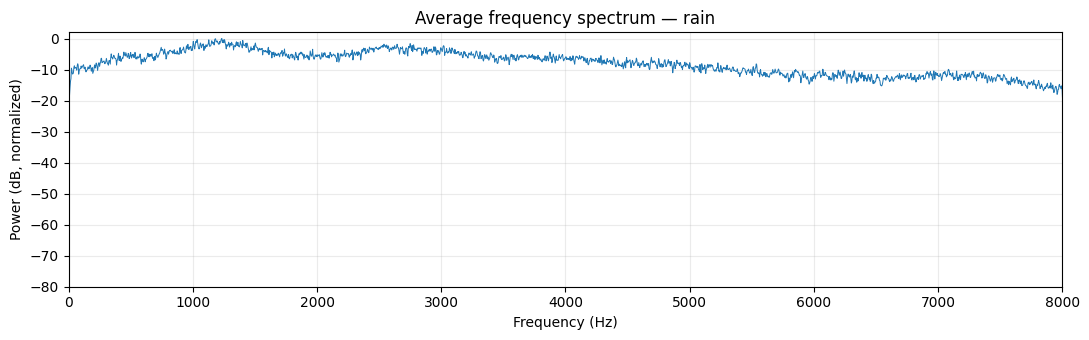

In [3]:
freq, psd = welch(x, fs=sr, nperseg=4096)
psd_db = 10 * np.log10(psd / (np.max(psd) + 1e-12) + 1e-12)
plt.figure(figsize=(11, 3.5))
plt.plot(freq, psd_db, linewidth=0.7)
plt.xlim(0, sr/2)
plt.ylim(-80, 2)
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (dB, normalized)")
plt.title("Average frequency spectrum — rain")
plt.grid(alpha=0.25)
plt.tight_layout()
plt.savefig(RESULTS / "frequency_spectrum.png", dpi=200)
plt.show()


## 3. STFT spectrograms

- **512 samples:** 32 ms window; bin spacing \(16000/512 = 31.25\) Hz. Shorter window improves temporal localization.
- **2048 samples:** 128 ms window; bin spacing \(16000/2048 = 7.8125\) Hz. Longer window improves frequency resolution.
- Hop length for both: 160 samples = 10 ms. The hop is frame spacing; it is not the window duration.

Color is normalized to each spectrogram's maximum. This makes patterns visible, but the colors are not absolute sound levels.


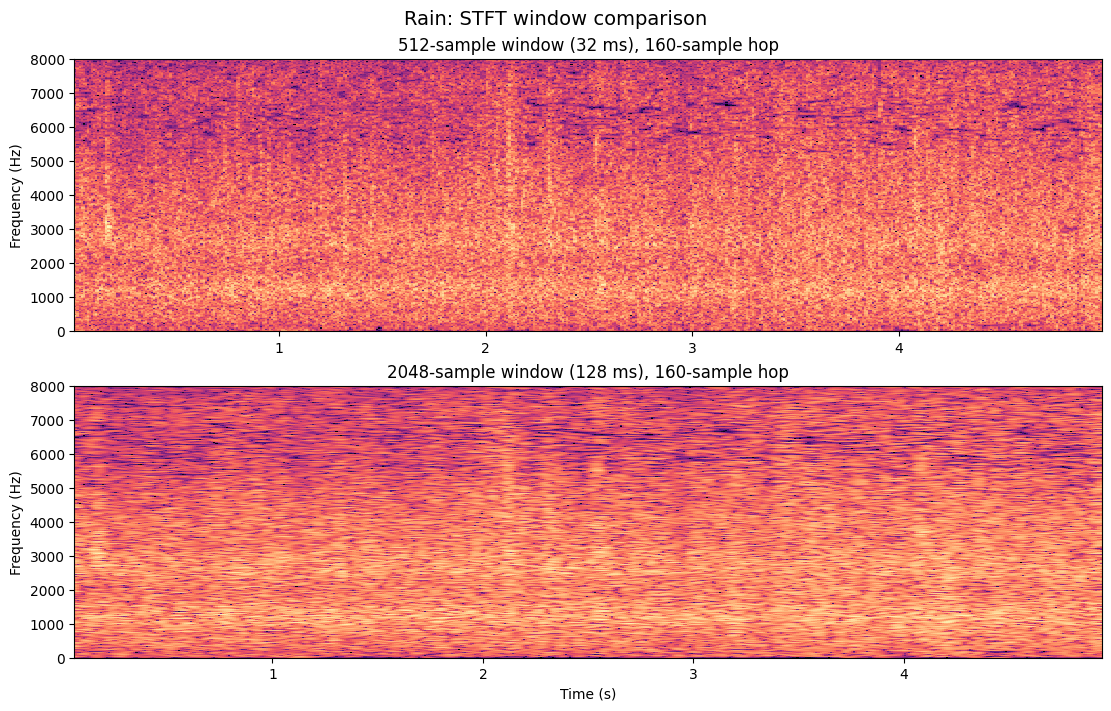

In [4]:
fig, axes = plt.subplots(2, 1, figsize=(11, 7), constrained_layout=True)
for ax, n in zip(axes, WINDOWS):
    f, t_frames, Z = stft(x, fs=sr, window="hann", nperseg=n,
                           noverlap=n-HOP, nfft=n, boundary=None, padded=False)
    spec_db = 20 * np.log10(np.abs(Z) / (np.max(np.abs(Z)) + 1e-12) + 1e-12)
    ax.pcolormesh(t_frames, f, spec_db, shading="auto",
                  vmin=-60, vmax=0, cmap="magma")
    ax.set_ylim(0, sr/2)
    ax.set_ylabel("Frequency (Hz)")
    ax.set_title(f"{n}-sample window ({1000*n/sr:.0f} ms), 160-sample hop")
axes[-1].set_xlabel("Time (s)")
fig.suptitle("Rain: STFT window comparison", fontsize=14)
fig.savefig(RESULTS / "spectrogram_comparison.png", dpi=200)
plt.show()


## 4. Selected interval and frequency region

I selected **2.0–2.5 seconds** and inspected **1–6 kHz**. The interval is a little louder than the first two seconds: its RMS amplitude is approximately 0.1455 compared with 0.1247 in 0–1 s (normalized waveform). The spectrogram shows energy distributed broadly across the selected frequency range rather than a single narrow tone.

The selected region is plotted for both window sizes below.


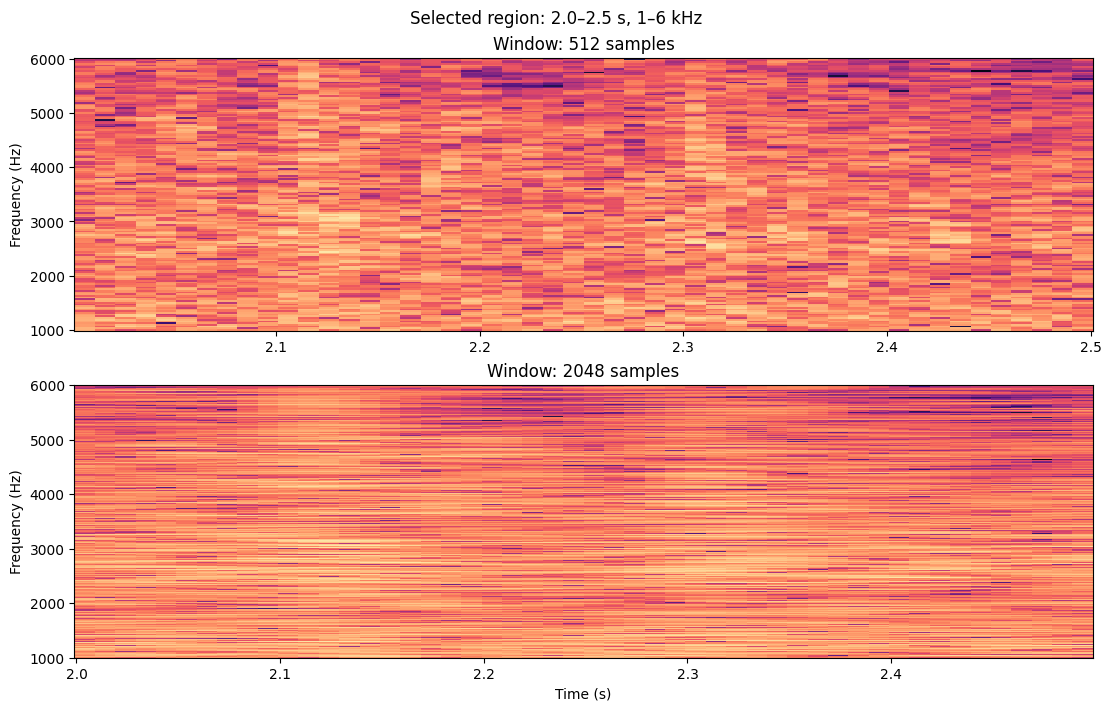

In [5]:
TIME_START, TIME_END = 2.0, 2.5
FREQ_LOW, FREQ_HIGH = 1000, 6000
fig, axes = plt.subplots(2, 1, figsize=(11, 7), constrained_layout=True)
for ax, n in zip(axes, WINDOWS):
    f, t_frames, Z = stft(x, fs=sr, window="hann", nperseg=n,
                           noverlap=n-HOP, nfft=n, boundary=None, padded=False)
    spec_db = 20 * np.log10(np.abs(Z) / (np.max(np.abs(Z)) + 1e-12) + 1e-12)
    mt = (t_frames >= TIME_START) & (t_frames <= TIME_END)
    mf = (f >= FREQ_LOW) & (f <= FREQ_HIGH)
    ax.pcolormesh(t_frames[mt], f[mf], spec_db[np.ix_(mf, mt)],
                  shading="auto", vmin=-60, vmax=0, cmap="magma")
    ax.set_ylabel("Frequency (Hz)")
    ax.set_title(f"Window: {n} samples")
axes[-1].set_xlabel("Time (s)")
fig.suptitle("Selected region: 2.0–2.5 s, 1–6 kHz")
fig.savefig(RESULTS / "selected_region.png", dpi=200)
plt.show()


## 5. Interpretation

In the rain recording, the waveform and spectrogram show a continuous noise-like sound with small fluctuations in amplitude. In the selected 2.0–2.5 s interval, the normalized RMS amplitude is higher than in the first second, and the selected frequency region contains broadly distributed energy.

The **512-sample window** is shorter (32 ms), so the spectrogram can localize rapid changes more closely in time. Its frequency-bin spacing is coarser (31.25 Hz), so narrow frequency details are less separated.

The **2048-sample window** is longer (128 ms), so its frequency-bin spacing is finer (7.8125 Hz). However, a brief change is averaged over a longer span and therefore appears less sharply located in time.

## 6. Limitation

The STFT has a time-frequency resolution trade-off: improving frequency resolution with a longer window reduces temporal localization. Also, this is a five-second recording and only one interval was examined, so the observations may not represent all rain recordings.

## AI assistance disclosure

AI assistance was used to scaffold the code and explain signal-processing concepts. I inspected the actual plots and recording and checked the outputs. Before submitting, I should be able to explain each code section and the conclusions.
